# Semantic Role Labelling with LogReg

-Matt

Please find the files to download [here](https://drive.google.com/drive/folders/1AGpUh4PpvRzUHPMHsqk2bCkXL6XiA-PX?usp=sharing)

In [1]:
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction import DictVectorizer
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    classification_report,
    confusion_matrix,
)
from spacy.tokens import Doc
import pickle
import matplotlib.pyplot as plt
import en_core_web_md
from tabulate import tabulate

E:\Software\Anaconda\Lib\site-packages\spacy\util.py:910: UserWarning: [W095] Model 'en_core_web_md' (3.7.1) was trained with spaCy v3.7.2 and may not be 100% compatible with the current version (3.8.4). If you see errors or degraded performance, download a newer compatible model or retrain your custom model with the current spaCy version. For more details and available updates, run: python -m spacy validate
  warnings.warn(warn_msg)


In [2]:
nlp = en_core_web_md.load()

## Change conllu into conll

In [3]:
def convert_conllu_to_conll(input_file, output_file):
    """
    Converts a CoNLL-U formatted file to a CoNLL formatted file by removing the first column
    and preserving token data. Metadata lines starting with '#' are ignored.

    Args:
        input_file (str): Path to the input CoNLL-U file.
        output_file (str): Path to the output CoNLL file.

    """
    with open(input_file, "r", encoding="utf-8") as infile, open(output_file, "w", encoding="utf-8") as outfile:
        for line in infile:
            if line.startswith("# "):
                continue

            if line.strip():
                columns = line.strip().split("\t")
                outfile.write("\t".join(columns[1:]) + "\n")
            else:
                outfile.write("\n")

In [4]:
convert_conllu_to_conll('./en_ewt-up-train.conllu', './train.conll')
convert_conllu_to_conll('./en_ewt-up-test.conllu', './test.conll')
convert_conllu_to_conll('./en_ewt-up-dev.conllu', './dev.conll')

## Duplicate Lines

In [5]:
def create_dupfile(inputfile, outputfile):
    """
    Processes a CoNLL file, generates duplications for rows with arguments,
    and writes them to an output file. Each duplication is labeled with a 
    sentence number.

    Args:
        inputfile (str): Path to the input CoNLL file.
        outputfile (str): Path to the output file with duplications.
    """
    fixed_columns = [
        "Form", "Lemma", "POS", "XPOS", "Morph", "Head", "Deprel", "Deps", "Misc", "Frame"
    ]

    rows = []
    max_columns = 0
    sentence_number = 1

    with open(inputfile, 'r', encoding='utf-8') as file:
        for line in file:
            line = line.strip()
            if not line:
                sentence_number += 1
                continue
            if line.startswith("# "):
                continue
            row = line.split('\t')
            max_columns = max(max_columns, len(row))
            rows.append([sentence_number] + row)

    num_fixed_columns = len(fixed_columns)
    num_dynamic_columns = max_columns - num_fixed_columns

    dynamic_columns = [f'Args{i + 1}' for i in range(num_dynamic_columns)]

    column_names = ["Sentence"] + fixed_columns + dynamic_columns

    df = pd.DataFrame(rows, columns=column_names).fillna('')

    sentences = df.groupby('Sentence', sort=False)

    output_columns = [
        "Sentence", "Form", "Lemma", "POS", "XPOS", "Morph", "Head", "Deprel", "Deps", "Misc", "Frame", "Args"
    ]

    with open(outputfile, 'w', encoding='utf-8') as newfile:
        for sentence_number, group in sentences:
            if (group['Frame'] == '_').all():
                continue

            duplications = []

            for i in range(num_dynamic_columns):
                arg_col = f'Args{i + 1}'

                if arg_col in group and not group[arg_col].empty:
                    if group[arg_col].fillna('').astype(str).apply(str.isalpha).any():
                        duplication = group.copy()
                        duplication['Sentence'] = f"{sentence_number}_{i + 1}"
                        duplication['Args'] = duplication[arg_col]
                        duplication = duplication[output_columns]
                        duplications.append(duplication)

            for dup in duplications:
                dup.to_csv(newfile, sep='\t', header=False, index=False)

In [6]:
create_dupfile('./train.conll', './dup_train.txt')
create_dupfile('./test.conll', './dup_test.txt')
create_dupfile('./dev.conll', './dup_dev.txt')

## Statistics

In [7]:
def read_conll(file):
    """
    Reads a CoNLL file and returns a list of dictionaries where each dictionary represents a token 
    with its corresponding features.

    Args:
        file (str): Path to the CoNLL file to be read.

    Returns:
        list: A list of dictionaries, each containing token information.
    """
    data = []
    with open(file, 'r', encoding='utf8') as infile:
        for line in infile:
            components = line.rstrip('\n').split()
            if len(components) > 0:
                col_dict = {
                    'Sentence': components[0],
                    'Form': components[1],
                    'Lemma': components[2],
                    'POS': components[3],
                    'XPOS': components[4],
                    'Morph': components[5],
                    'Head': components[6],
                    'Deprel': components[7],
                    'Deps': components[8],
                    'Misc': components[9] if 9 < len(components) else None,
                    'Frame': components[10] if 10 < len(components) else None,
                    'Args': components[11] if 11 < len(components) else None
                }
                data.append(col_dict)
    return data

In [8]:
train = pd.DataFrame.from_dict(read_conll('./dup_train.txt'))
test = pd.DataFrame.from_dict(read_conll('./dup_test.txt'))
dev = pd.DataFrame.from_dict(read_conll('./dup_dev.txt'))

In [9]:
train[:5]

,Sentence,Form,Lemma,POS,XPOS,Morph,Head,Deprel,Deps,Misc,Frame,Args
0,1_1,Al,Al,PROPN,NNP,Number=Sing,0,root,0:root,SpaceAfter=No,_,_
1,1_1,-,-,PUNCT,HYPH,_,1,punct,1:punct,SpaceAfter=No,_,_
2,1_1,Zaman,Zaman,PROPN,NNP,Number=Sing,1,flat,1:flat,_,_,_
3,1_1,:,:,PUNCT,:,_,1,punct,1:punct,_,_,_
4,1_1,American,american,ADJ,JJ,Degree=Pos,6,amod,6:amod,_,_,_


In [10]:
def count_sentences_tokens(file_path):
    """
    Counts the number of sentences and tokens in a CoNLL file.

    Args:
        file_path (str): Path to the CoNLL file.

    Returns:
        tuple: A tuple containing two integers:
               - The number of sentences
               - The number of tokens in the file
    """
    num_sentences = 0
    num_tokens = 0

    with open(file_path, 'r', encoding='utf8') as f:
        for line in f:
            line = line.strip()
            if line:
                num_tokens += 1
            else:
                num_sentences += 1

    if num_tokens > 0 and line:
        num_sentences += 1

    return num_sentences, num_tokens


pre_train = count_sentences_tokens('./train.conll')
pre_test = count_sentences_tokens('./test.conll')
pre_dev = count_sentences_tokens('./dev.conll')

In [11]:

print(f"""
    {"Before Preprocessing"}
    {"Train:"}
    {"Total number of sentences in the Text:":<52} {pre_train[0]}
    {"Total number of words in the Text:":<52} {pre_train[1]}
    {"Dev:"}
    {"Total number of sentences in the Text:":<52} {pre_dev[0]}
    {"Total number of words in the Text:":<52} {pre_dev[1]}
    {"Test:"}
    {"Total number of sentences in the Text:":<52} {pre_test[0]}
    {"Total number of words in the Text:":<52} {pre_test[1]}
    {"\n"}
    {"After Preprocessing"}
    {"Train:"}
    {"Total number of sentences in the Text:":<52} {len(set(train['Sentence']))}
    {"Total number of words in the Text:":<52} {len(train)}
    {"Dev:"}
    {"Total number of sentences in the Text:":<52} {len(set(dev['Sentence']))}
    {"Total number of words in the Text:":<52} {len(dev)}
    {"Test:"}
    {"Total number of sentences in the Text:":<52} {len(set(test['Sentence']))}
    {"Total number of words in the Text:":<52} {len(test)}
    """)


    Before Preprocessing
    Train:
    Total number of sentences in the Text:               12543
    Total number of words in the Text:                   204609
    Dev:
    Total number of sentences in the Text:               2002
    Total number of words in the Text:                   25150
    Test:
    Total number of sentences in the Text:               2077
    Total number of words in the Text:                   25097
    

    After Preprocessing
    Train:
    Total number of sentences in the Text:               40482
    Total number of words in the Text:                   1028264
    Dev:
    Total number of sentences in the Text:               4977
    Total number of words in the Text:                   105070
    Test:
    Total number of sentences in the Text:               4799
    Total number of words in the Text:                   101152
    


In [12]:


data = [
    ["Train Sentences", pre_train[0], len(set(train["Sentence"]))],
    ["Train Tokens", pre_train[1], len(train)],
    ["Dev Sentences", pre_dev[0], len(set(dev["Sentence"]))],
    ["Dev Tokens", pre_dev[1], len(dev)],
    ["Test Sentences", pre_test[0], len(set(test["Sentence"]))],
    ["Test Tokens", pre_test[1], len(test)],
]

table = tabulate(data, headers=[
                 "Dataset", "Before Preprocessing", "After Preprocessing"], tablefmt="grid")
print(table)

+-----------------+------------------------+-----------------------+
| Dataset         |   Before Preprocessing |   After Preprocessing |
+=================+========================+=======================+
| Train Sentences |                  12543 |                 40482 |
+-----------------+------------------------+-----------------------+
| Train Tokens    |                 204609 |               1028264 |
+-----------------+------------------------+-----------------------+
| Dev Sentences   |                   2002 |                  4977 |
+-----------------+------------------------+-----------------------+
| Dev Tokens      |                  25150 |                105070 |
+-----------------+------------------------+-----------------------+
| Test Sentences  |                   2077 |                  4799 |
+-----------------+------------------------+-----------------------+
| Test Tokens     |                  25097 |                101152 |
+-----------------+---------------

## Features

The features that are used in this model are:

* <b>Dependency Path with Lemma (Given Feature)</b>:<br>
  The dependency path encodes important information about the grammatical structure, such as the direction and type of syntactic relations (e.g., subject, object, modifier). By including the predicate lemma, the feature also adds semantic consistency, which helps the model generalize across different forms of the same verb.

* <b>Named Entity with Lemma</b>:<br>
  This is useful for Semantic Role Labeling (SRL) because named entities often play specific roles in a sentence, such as agents or patients in a predicate's argument structure. By including the named entity type along with the lemma, this feature allows the Logistic Regression model to incorporate important semantic information about the word, such as whether it is a named entity, and how it relates to the predicate

* <b>Part of Speech Context</b>:<br>
  It captures the part-of-speech (POS) tags of a word and its immediate neighbors (previous and next words). This feature is valuable for Semantic Role Labeling (SRL) because the POS of a word can provide critical syntactic and semantic information about its role in the sentence. Including the POS tags of neighboring words (preceding and following) offers additional context, as the grammatical structure around a word can influence its role in the sentence.

In [13]:
def extract_gold(df):
    """
    Extracts gold labels for argument extraction from the provided DataFrame.

    Args:
        df (pandas.DataFrame): The input DataFrame containing tokenized data.

    Returns:
        list: A list of gold labels, either the argument or 'O' for non-arguments.
    """
    sentences = df.groupby("Sentence", sort=False)
    targets = []
    for sentence_number, group in sentences:
        print(f"\rProgress:{sentence_number}", end="")
        group_list = group.to_dict(orient="records")
        for row in group_list:
            if row['Args'] == '_' or row['Args'] == 'V' or row['Args'] is None:
                targets.append('O')
            else:
                targets.append(row['Args'])
    return targets

In [14]:
def clean_data(df):
    """
    Cleans the input DataFrame by keeping only the data we are allowed to use.

    Args:
        df (pandas.DataFrame): The input DataFrame containing tokenized data.

    Returns:
        tuple: A tuple containing:
            - A cleaned DataFrame with 'Sentence', 'Form', and 'Predicate' columns.
            - A list of gold labels extracted from the 'Args' column.
    """
    gold = extract_gold(df)
    df["Predicate"] = df["Args"].apply(lambda x: 1 if x == "V" else 0)
    data = df[['Sentence', 'Form', "Predicate"]]
    print()
    return data, gold

In [15]:
clean_train, train_targets = clean_data(train)
clean_dev, dev_targets = clean_data(dev)
clean_test, test_targets = clean_data(test)

Progress:12543_50
Progress:2002_23
Progress:2077_10


In [16]:
clean_train[:10]

,Sentence,Form,Predicate
0,1_1,Al,0
1,1_1,-,0
2,1_1,Zaman,0
3,1_1,:,0
4,1_1,American,0
5,1_1,forces,0
6,1_1,killed,1
7,1_1,Shaikh,0
8,1_1,Abdullah,0
9,1_1,al,0


In [17]:
def find_path(word, predicate):
    """
    Finds the path between two tokens (word and predicate) in a dependency tree.

    Args:
        word (spacy.tokens.Token): The word token to start the path from.
        predicate (spacy.tokens.Token): The predicate token to find the path to.

    Returns:
        list: A list representing the path from the word to the predicate, with dependency relations.
              Returns ['None'] if no path exists.
    """
    word_ancestors = {token: i for i, token in enumerate(word.ancestors)}
    predicate_ancestors = {token: i for i,
                           token in enumerate(predicate.ancestors)}

    if predicate.head == predicate:
        path = []
        node = word
        while node != predicate:
            if node == node.head:
                return ['None']
            path.append(node.dep_ + "↑")
            node = node.head
        # path.append(predicate.dep_ + "*")
        return path

    if word.head == word:
        path = []
        node = predicate
        while node != word:
            if node == node.head:
                return ['None']
            path.append(node.dep_ + "↓")
            node = node.head
        # path.append(word.dep_ + "*")
        return path

    common_ancestors = set(word_ancestors.keys()) & set(
        predicate_ancestors.keys())
    if not common_ancestors:
        return ['None']

    lca = min(common_ancestors,
              key=lambda token: word_ancestors[token] + predicate_ancestors[token])

    path = []
    node = word
    while node != lca:
        path.append(node.dep_ + "↑")
        node = node.head

    node = predicate
    down_path = []
    while node != lca:
        down_path.append(node.dep_ + "↓")
        node = node.head

    # return path + [lca.dep_ + "*"] + list(reversed(down_path))
    return path + list(reversed(down_path))

In [18]:
def findContext(sent, i):
    """
    Finds the context of a word in a sentence which is it's and it's neighbor's POS.

    Args:
        sent (spacy.tokens.Doc): A SpaCy document containing the sentence.
        i (int): The index of the word in the sentence.

    Returns:
        str: A string representing the context of the word, combining the POS tags of the previous, current, and next words.
             '[START]' and '[END]' are used for the boundaries of the sentence.
    """
    if i == 0:
        pre = '[START]'
    else:
        pre = sent[i-1].pos_

    current = sent[i].pos_

    if i == len(sent)-1:
        next = '[END]'
    else:
        next = sent[i+1].pos_

    return pre+'_'+current+'_'+next

In [19]:
def prepare_sentence(row, group, idx):
    """
    Prepares sentence-level features for a given word and predicate.

    Args:
        row (pandas.Series): The current row containing information about a word.
        group (pandas.DataFrame): The sentence group with token-level data.
        idx (int): The index of the word within the sentence.

    Returns:
        dict: A dictionary containing features like entity and lemma information, dependency path, and context.
    """
    sentence = group['Form'].tolist()
    predicate = group['Predicate'].tolist()
    word = row['Form']
    word_idx = idx
    pred_idx = predicate.index(1)

    if isinstance(sentence, list):
        spacy_doc = Doc(nlp.vocab, words=sentence)
        processed_doc = nlp(spacy_doc)
    else:
        processed_doc = nlp(sentence)

    doc_word = processed_doc[word_idx]
    doc_pred = processed_doc[pred_idx]

    path = find_path(doc_word, doc_pred)

    dir_dep = " ".join(path)
    lemma = doc_pred.lemma_
    depLemma = dir_dep + " " + lemma

    if doc_word.ent_type_:
        entLemma = doc_word.ent_type_ + " " + lemma
    else:
        entLemma = "O " + lemma

    contextPos = findContext(processed_doc, idx)
    PosDistLemma = " ".join([doc_word.pos_, str(word_idx - pred_idx), lemma])

    data = {
        "entLemma": entLemma,
        "depLemma": depLemma,
        "contextPos": contextPos
    }
    return data

In [20]:
def extract_features(df):
    """
    Extracts features for each word in the sentences from the given DataFrame.

    Args:
        df (pandas.DataFrame): DataFrame containing sentence-level data with token information.

    Returns:
        list: A list of dictionaries, each containing features extracted for individual words in the sentences.
    """
    sentences = df.groupby("Sentence", sort=False)
    feature_sentences = []
    print()
    x = 1
    for sentence_number, group in sentences:
        i = 0
        print(f"\rProgress:{sentence_number}", end="")
        group_list = group.to_dict(orient="records")
        for row in group_list:
            features = prepare_sentence(row, group, i)
            feature_sentences.append(features)
            i = i+1
    return feature_sentences

In [30]:
train_feats = extract_features(clean_train)


Progress:12543_50

In [31]:
train_feats[:5]

[{'entLemma': 'PERSON kill',
  'depLemma': 'compound↑ nsubj↑ kill',
  'contextPos': '[START]_PROPN_PUNCT'},
 {'entLemma': 'PERSON kill',
  'depLemma': 'punct↑ nsubj↑ kill',
  'contextPos': 'PROPN_PUNCT_PROPN'},
 {'entLemma': 'PERSON kill',
  'depLemma': 'nsubj↑ kill',
  'contextPos': 'PUNCT_PROPN_PUNCT'},
 {'entLemma': 'O kill',
  'depLemma': 'punct↑ kill',
  'contextPos': 'PROPN_PUNCT_ADJ'},
 {'entLemma': 'NORP kill',
  'depLemma': 'amod↑ nsubj↑ kill',
  'contextPos': 'PUNCT_ADJ_NOUN'}]

In [32]:
with open('trainFeats.pkl', 'wb') as file:

    pickle.dump(train_feats, file)

In [33]:
dev_feats = extract_features(clean_dev)


Progress:2002_23

In [34]:
with open('devFeats.pkl', 'wb') as file:

    pickle.dump(dev_feats, file)

In [35]:
test_feats = extract_features(clean_test)


Progress:2077_10

In [36]:
with open('testFeats.pkl', 'wb') as file:

    pickle.dump(test_feats, file)

In [21]:

with open('testFeats.pkl', 'rb') as file:
    test_feats = pickle.load(file)

with open('devFeats.pkl', 'rb') as file:
    dev_feats = pickle.load(file)

with open('trainFeats.pkl', 'rb') as file:
    train_feats = pickle.load(file)

## Model Creation

In [22]:
def create_classifier(train_features, train_targets):
    """
    Trains a logistic regression classifier using the provided feature set and target labels.

    Args:
        train_features (list of dict): List of feature dictionaries representing the training data.
        train_targets (list): List of target labels corresponding to the training data.

    Returns:
        tuple: A tuple containing:
            - model: The trained logistic regression model.
            - vec: The vectorizer used to transform the feature set.
            - encoder: The label encoder used to encode the target labels.
    """
    vec = DictVectorizer()
    features_vectorized = vec.fit_transform(train_features)
    encoder = LabelEncoder()
    y_encoded = encoder.fit_transform(train_targets)

    logreg = LogisticRegression(max_iter=1000, solver='lbfgs')
    model = logreg.fit(features_vectorized, y_encoded)

    return model, vec, encoder

In [23]:
log_model, log_vec, label_encoder = create_classifier(
    train_feats, train_targets)

In [24]:
with open('model.pkl', 'wb') as file:
    pickle.dump(log_model, file)

with open('vec.pkl', 'wb') as file:
    pickle.dump(log_vec, file)

with open('label_encoder.pkl', 'wb') as file:
    pickle.dump(label_encoder, file)

## Predict values for the data

In [25]:
def classify_data(model, vec, inputdata):
    """
    Classifies input data using a trained model and vectorizer.

    Args:
        model: The trained classification model (e.g., Logistic Regression).
        vec: The vectorizer used to transform the input features.
        inputdata (list of dict): List of feature dictionaries to be classified.

    Returns:
        numpy.ndarray: The predicted labels for the input data.
    """
    features = vec.transform(inputdata)
    predictions = model.predict(features)
    return predictions

In [26]:
for idx, i in enumerate(test_targets):
    if i not in label_encoder.classes_:
        test_targets[idx] = 'O'

In [27]:
pred = classify_data(log_model, log_vec, test_feats)

encoded_test = list(label_encoder.transform(test_targets))

In [28]:
pred[:5]

array([45, 45, 45, 45, 45], dtype=int64)

In [29]:
encoded_test[:5]

[45, 45, 1, 45, 45]

## Evaluation

In [30]:
def evaluate_file(pred, gold, label_encoder):
    """
    Evaluates model predictions against gold labels using classification metrics.

    Args:
        pred (numpy.ndarray): Array of predicted labels.
        gold (numpy.ndarray): Array of true labels (gold labels).
        label_encoder (LabelEncoder): The label encoder used to map labels back to their original form.

    Prints:
        classification_report: The classification report including precision, recall, and F1 scores for each label.
        ConfusionMatrixDisplay: The confusion matrix visualized for model evaluation.
    """
    pred = label_encoder.inverse_transform(pred)
    gold = label_encoder.inverse_transform(gold)

    labels = sorted(set(pred).union(set(gold)))
    print(
        classification_report(
            gold,
            pred,
            labels=labels,
            zero_division=0,
        )
    )

    cf_matrix = confusion_matrix(gold, pred)

    # reduce the weightage of O to make the rest clearer
    if 'O' in labels:
        o_index = labels.index("O")
        cf_matrix[o_index, o_index] /= 100

    cf_display = ConfusionMatrixDisplay(
        confusion_matrix=cf_matrix,
        display_labels=labels,
    )

    fig, ax = plt.subplots(figsize=(18, 18))
    cf_display.plot(cmap="cividis", xticks_rotation=45, ax=ax)

    plt.title("Confusion Matrix", fontsize=14)
    plt.xlabel("Predicted Labels", fontsize=12)
    plt.ylabel("True Labels", fontsize=12)

              precision    recall  f1-score   support

        ARG0       0.81      0.52      0.64      1733
        ARG1       0.84      0.52      0.65      3241
    ARG1-DSP       0.00      0.00      0.00         4
        ARG2       0.77      0.53      0.63      1129
        ARG3       0.64      0.19      0.29        74
        ARG4       0.45      0.43      0.44        56
        ARG5       0.00      0.00      0.00         1
        ARGA       0.00      0.00      0.00         2
    ARGM-ADJ       0.83      0.26      0.39       228
    ARGM-ADV       0.43      0.13      0.20       496
    ARGM-CAU       0.00      0.00      0.00        46
    ARGM-COM       0.00      0.00      0.00        13
    ARGM-CXN       1.00      0.17      0.29        12
    ARGM-DIR       0.44      0.09      0.14        47
    ARGM-DIS       0.69      0.27      0.39       182
    ARGM-EXT       0.83      0.36      0.50       105
    ARGM-GOL       0.00      0.00      0.00        24
    ARGM-LOC       0.71    

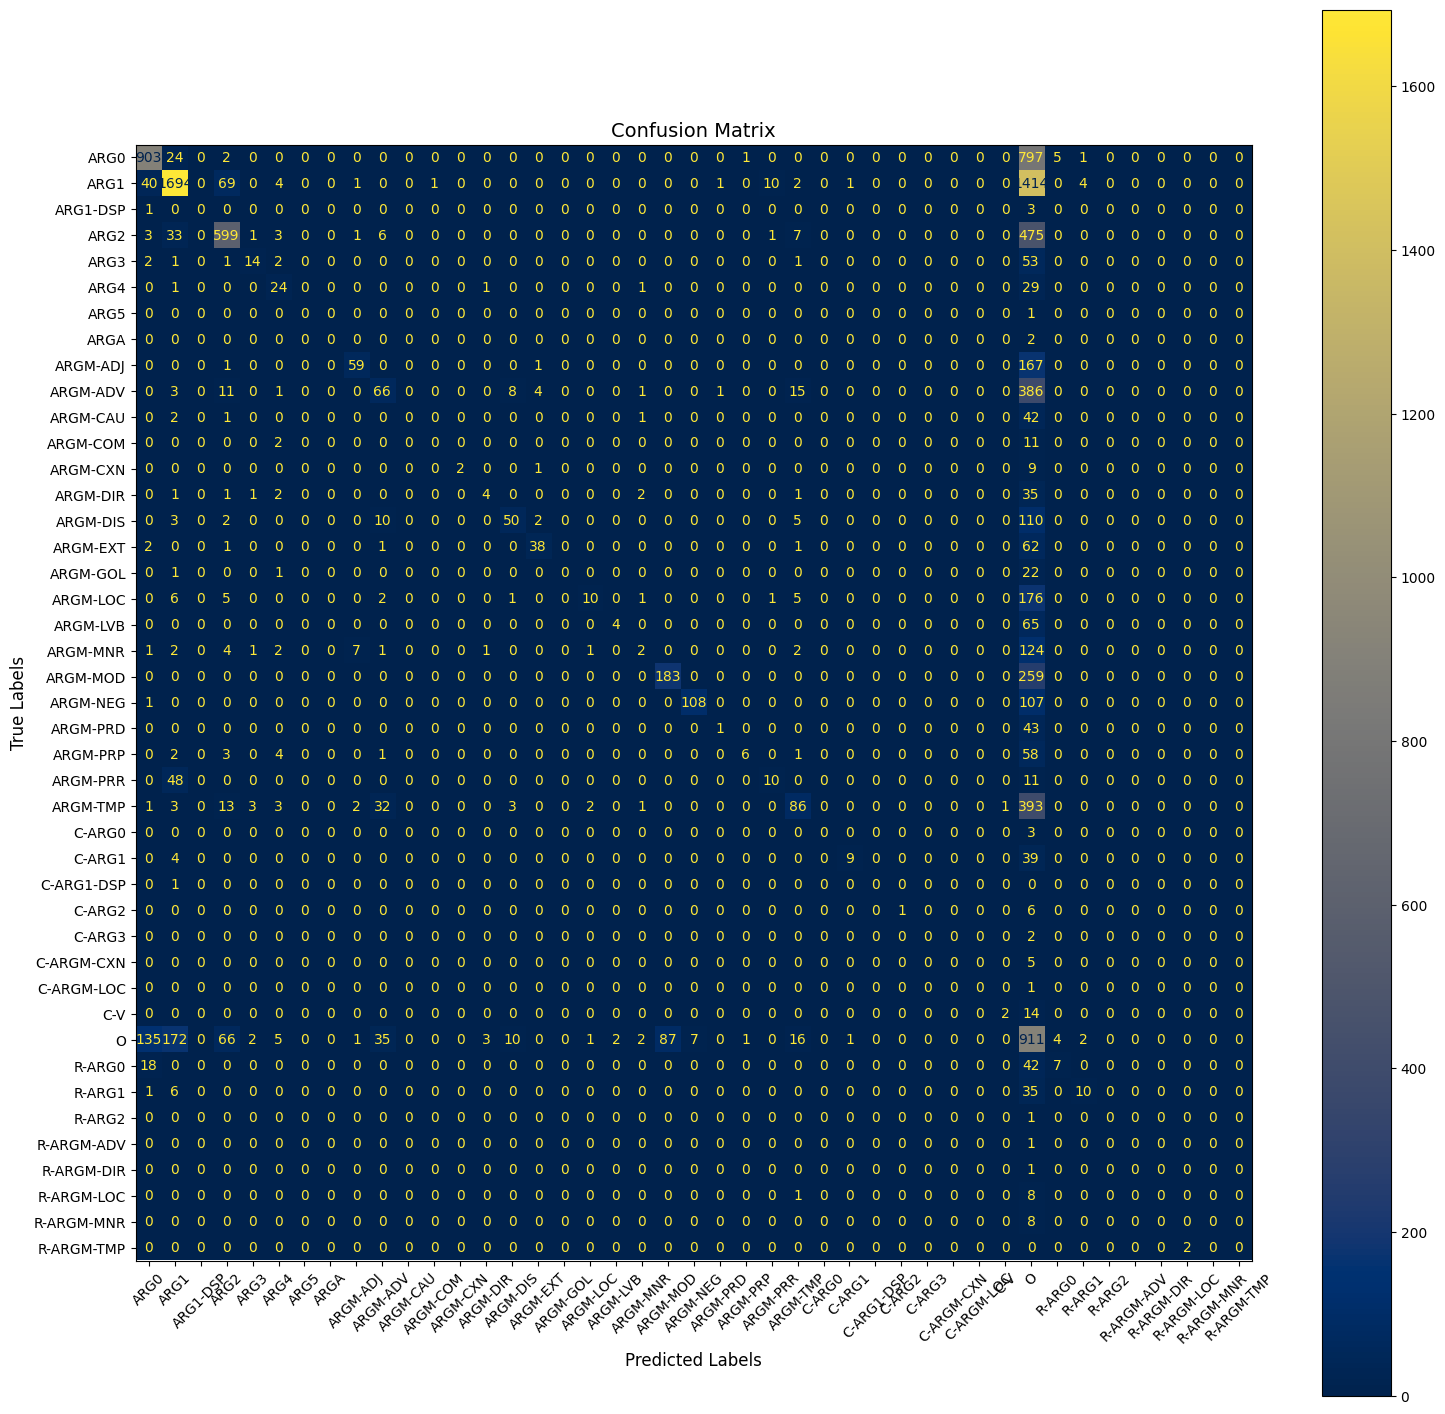

In [31]:
evaluate_file(list(pred), encoded_test, label_encoder)

The results of the Logistic Regression model for Semantic Role Labeling (SRL) using three features (dependency path, named entity recognition, and token POS) show a significant decline in performance compared to BERT, with an overall accuracy of 93%. However, there is a considerable imbalance in precision, recall, and F1 scores across different roles.

The easiest roles to identify are still ARG0 and ARG1, with precision scores of 0.84, though the recall (0.41 for both) is relatively low. This results in an F1 score of 0.55, indicating that while these roles are correctly identified in some cases, many instances are missed. The ARG2 role also performs reasonably well, with a precision of 0.76 and a recall of 0.49, yielding an F1 score of 0.59.

On the other hand, several roles show extremely poor performance, particularly ARG5, ARGM-CAU, ARGM-COM, ARGM-DIR, and ARGM-GOL, which all have zero recall and F1 scores, indicating that the model fails to identify these roles. Roles like ARG3, ARG4, and ARGM-ADV also perform poorly, with F1 scores ranging from 0.16 to 0.31, pointing to the challenges the model faces with less frequent or more complex roles.

The macro average scores (precision: 0.37, recall: 0.11, F1: 0.16) indicate that the model has difficulty with underrepresented semantic roles. These roles likely suffer from a lack of sufficient training data or more intricate syntactic and semantic features that the current feature set cannot effectively capture.

In contrast, the weighted average scores (precision: 0.92, recall: 0.93, F1: 0.92) suggest that the model performs well on more frequent roles, achieving high precision and recall. However, the imbalance in performance across different semantic roles is a clear issue, which is reflected in the significant drop in recall for many roles, particularly those with lower support.

In [32]:
def output_tsv(input_file, output_file, predictions, gold_labels):

    pred = list(predictions)
    pred = label_encoder.inverse_transform(pred)
    gold = label_encoder.inverse_transform(gold_labels)

    with open(output_file, "w") as outfile:
        index = 0

        with open(input_file, "r") as infile:
            for line in infile:
                if len(line.rstrip("\n").split()) > 0:
                    token = line.split()[3]

                    pred_label = pred[index]
                    gold_label = gold[index]

                    outfile.write(line.rstrip("\n") +
                                  f"\t{pred_label}\t{gold_label}\n")
                    index += 1

    print(f"Output written to {output_file}")

In [34]:
output_tsv('./dup_test.txt', './predictions.tsv', pred, encoded_test)

Output written to ./predictions.tsv


## Stand alone Sentence

In [35]:
# Load the model.pkl file into log_model
with open('model.pkl', 'rb') as model_file:
    log_model = pickle.load(model_file)

# Load the vec.pkl file into log_vec
with open('vec.pkl', 'rb') as vec_file:
    log_vec = pickle.load(vec_file)

# Load the vec.pkl file into log_vec
with open('label_encoder.pkl', 'rb') as vec_file:
    label_encoder = pickle.load(vec_file)

In [36]:
sent = ["The", "cat", "slept", "on", "the", "mat",
        "and", "the", "dog", "barked", "loudly", "."]
predicate = [0, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 0]


def find_nth_instance(lst, element, n):
    """
    Finds the index of the nth occurrence of a specified element in a list.

    Parameters:
    lst (list): The list to search within.
    element: The element to search for.
    n (int): The occurrence number to find (0-based index).

    Returns:
    int: The index of the nth occurrence of the element, or -1 if it doesn't exist.
    """
    count = 0
    for i, val in enumerate(lst):
        if val == element:
            if count == n:
                return i
            count += 1
    return -1


def stand_alone_sent(sent, predicate):
    """
    Processes a sentence with a list of predicate indicators and classifies each token 
    based on extracted features.

    Parameters:
    sent (list of str): The list of tokens in the sentence.
    predicate (list of int): The list indicating predicates (1 for predicate, 0 for non-predicate).

    Returns:
    pd.DataFrame: A DataFrame with token information (Form, Predicate, Prediction) for each token 
                  in the sentence, along with predicted labels.
    """
    pred_num = predicate.count(1)
    all_tokens = []
    for i in range(pred_num):
        for idx, ele in enumerate(sent):
            token = {
                "Sentence": i,
                "Form": ele,
                "Predicate": 1 if find_nth_instance(predicate, 1, i) == idx else 0
            }
            all_tokens.append(token)
    data = pd.DataFrame(all_tokens)
    feats = extract_features(data)

    pred = classify_data(log_model, log_vec, feats)
    pred = list(label_encoder.inverse_transform(pred))
    data['Prediction'] = pred
    return data


stand_alone_sent(sent, predicate)


Progress:1

,Sentence,Form,Predicate,Prediction
0,0,The,0,O
1,0,cat,0,O
2,0,slept,1,O
3,0,on,0,O
4,0,the,0,O
5,0,mat,0,O
6,0,and,0,O
7,0,the,0,O
8,0,dog,0,O
9,0,barked,0,O
